# Analisis Komparatif MLP dan CNN dengan Teknik Optimasi dan Regularisasi pada Klasifikasi Penyakit Daun Tomat
*Comparative Analysis of MLP and CNN with Optimization and Regularization Techniques for Tomato Leaf Disease Classification*

Notebook ini adalah **ringkasan alur kerja** yang memanggil modul pada repository (`prep_data.py`, `common.py`,
`run_all.py`, `analysis.py`, `inference.py`). Angka yang tampil berasal dari hasil tersimpan di folder `results/`
(identik dengan laporan). Atur `RETRAIN = True` untuk melatih ulang seluruh skenario (lama jika tanpa GPU).

**Alur:** 1 Setup -> 2 Data -> 3 EDA -> 4 Pipeline tf.data -> 5 Model -> 6 Pelatihan -> 7 Evaluasi -> 8 Dua fitur unik -> 9 Inferensi.

## 1. Setup

In [1]:
import os, sys, json, glob
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

RETRAIN = False                       # True = latih ulang semua skenario
ROOT = os.getcwd()
os.environ.setdefault("DATA_DIR", f"{ROOT}/data")
os.environ.setdefault("RES_DIR", f"{ROOT}/results")
sys.path.insert(0, ROOT)

import tensorflow as tf
import keras, sklearn
print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__, "| Keras", keras.__version__, "| scikit-learn", sklearn.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "tidak ada (CPU)")

I0000 00:00:1793958666.124307      86 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793958677.285078      86 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793958684.141050      86 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.3 | TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1
GPU: tidak ada (CPU)


## 2. Data
Dataset: PlantVillage, folder `raw/color` (10 kelas tomat). Jika `data/tomato64.npz` belum ada, jalankan langkah unduh pada README lalu `python prep_data.py pv/raw/color data`.
Persiapan data: hapus 14 duplikat persis (MD5), kelompokkan near-duplicate (dHash 256-bit), resize 64x64, split 70/15/15 stratified-grouped.

In [2]:
st = json.load(open("results/dataset_stats.json"))
print(f"Citra mentah: {st['n_raw']} | duplikat persis dibuang: {st['n_exact']} | setelah dedup: {st['n_after']}")
print(f"Near-duplicate: {st['near_pairs']} pasangan | split: {st['split']}")
import pandas as pd
df = pd.DataFrame({"kelas": st["classes"], "mentah": st["raw"], "dedup": st["dedup"], "train": st["train"], "val": st["val"], "test": st["test"],
                   "class_weight": np.round(st["class_weight"], 3)})
display(df)
print("Rasio ketidakseimbangan (mentah):", round(st["imbalance_raw"], 1), ": 1")

Citra mentah: 18160 | duplikat persis dibuang: 14 | setelah dedup: 18146
Near-duplicate: 3 pasangan | split: {'train': 12700, 'val': 2722, 'test': 2724}


,kelas,mentah,dedup,train,val,test,class_weight
0,Bacterial_spot,2127,2127,1489,318,320,0.853
1,Early_blight,1000,1000,700,150,150,1.814
2,Late_blight,1909,1901,1331,285,285,0.954
3,Leaf_Mold,952,952,667,142,143,1.904
4,Septoria_leaf_spot,1771,1771,1239,266,266,1.025
5,Spider_mites,1676,1676,1172,252,252,1.084
6,Target_Spot,1404,1404,983,211,210,1.292
7,Tomato_Yellow_Leaf_Curl_Virus,5357,5357,3750,804,803,0.339
8,Tomato_mosaic_virus,373,373,261,57,55,4.866
9,healthy,1591,1585,1108,237,240,1.146


Rasio ketidakseimbangan (mentah): 14.4 : 1


## 3. EDA

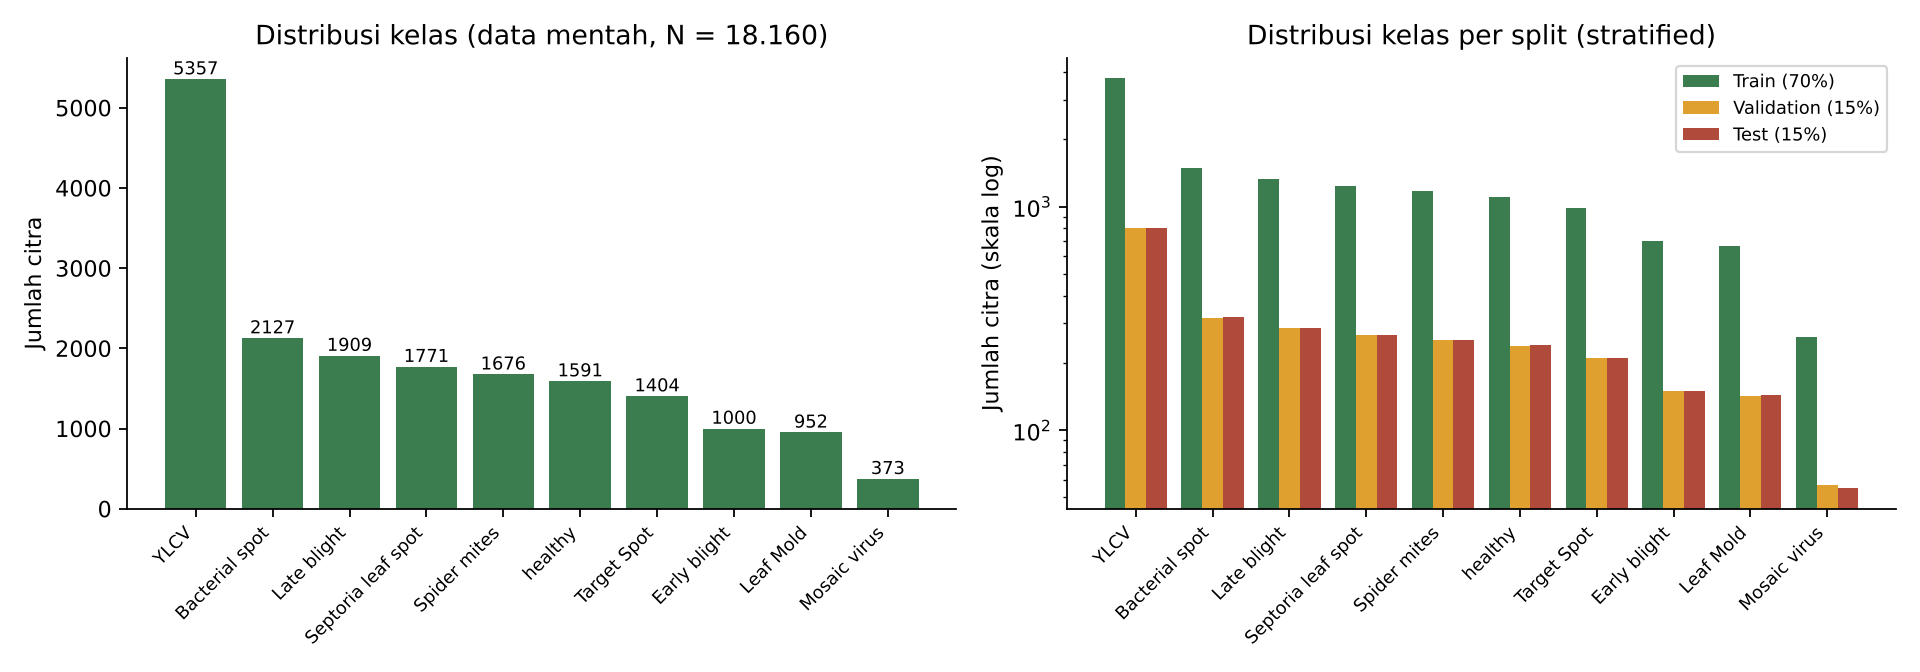

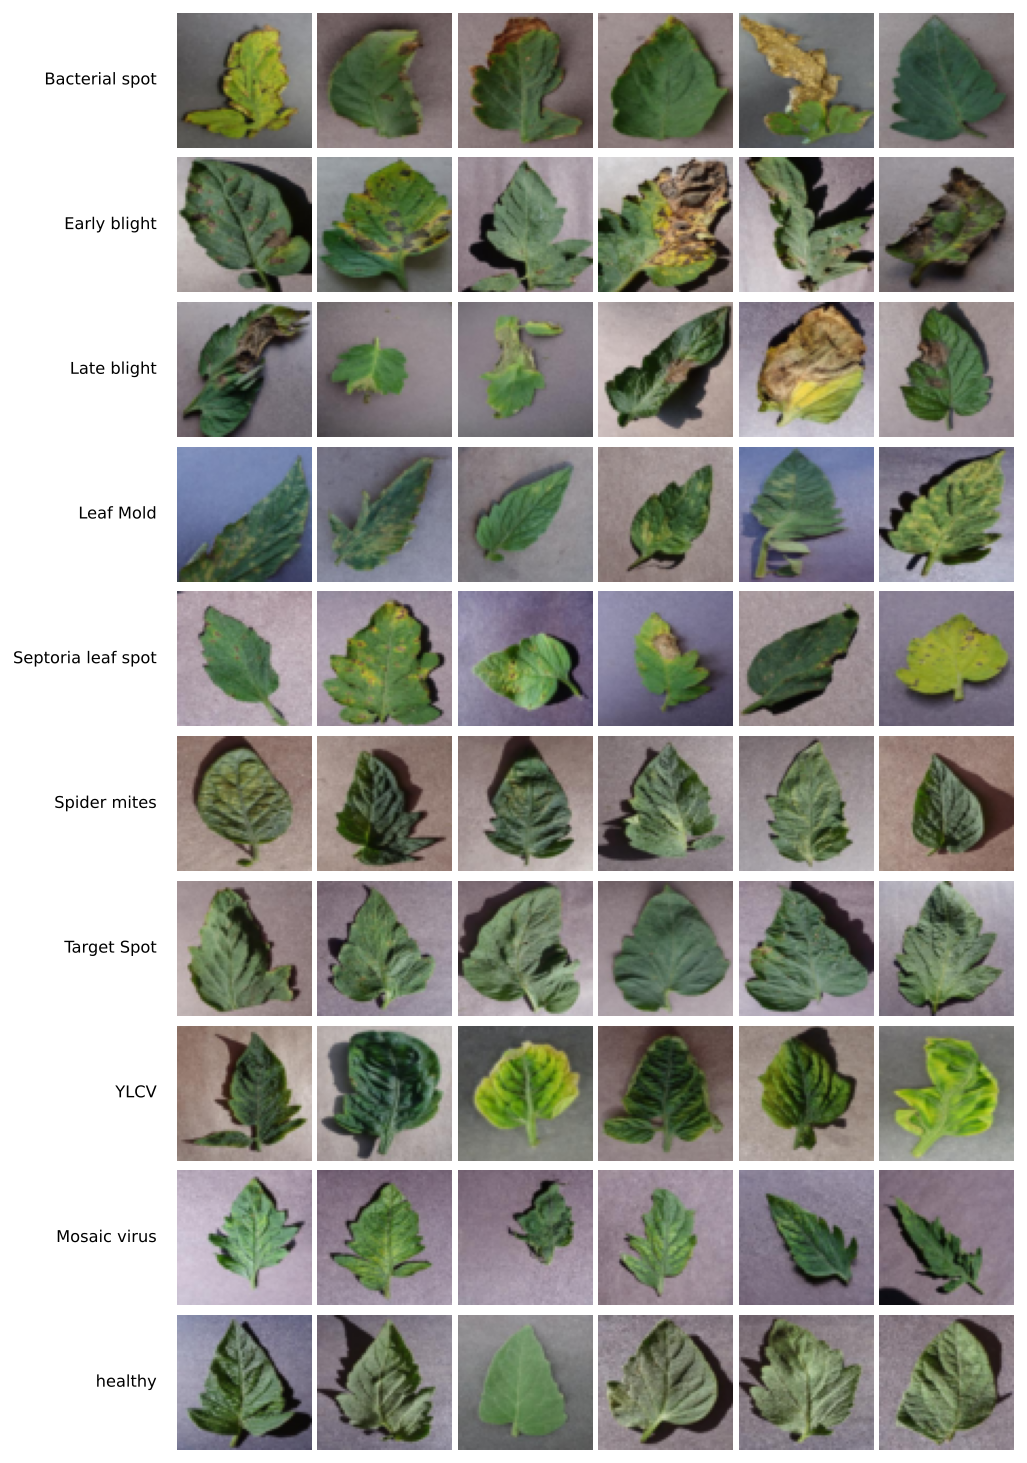

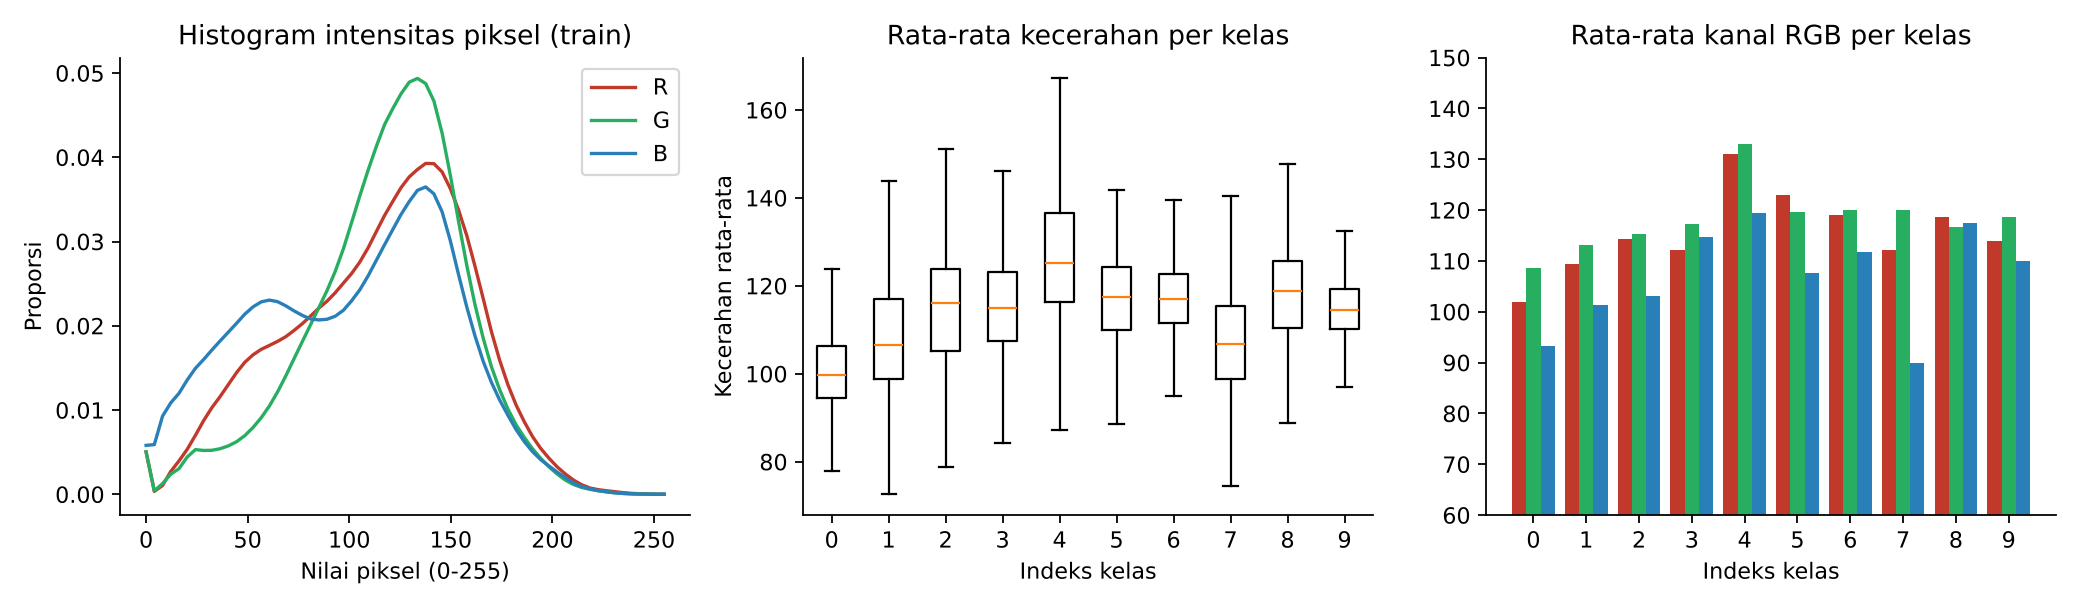

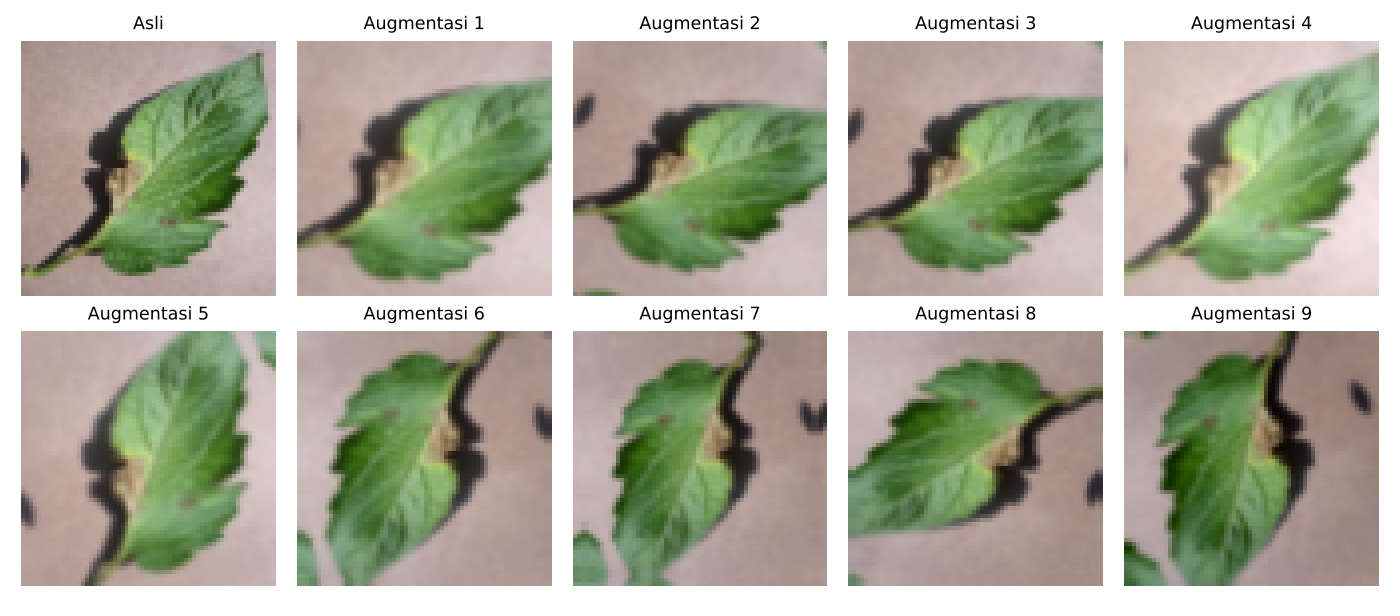

In [3]:
for fn in ["fig_class_distribution", "fig_samples_per_class", "fig_pixel_stats", "fig_augmentation"]:
    p = f"figures/{fn}.png"
    if os.path.exists(p): display(IPImage(p, width=760))

## 4. Input pipeline `tf.data`
`from_tensor_slices -> shuffle -> map(rescale) -> batch(64) -> prefetch` (materi pertemuan 2). Sel ini memerlukan `data/tomato64.npz`.

In [4]:
from common import *
if os.path.exists(f"{DATA}/tomato64.npz"):
    (Xtr, ytr), (Xva, yva), (Xte, yte), Xood, class_names = load_data()
    print("Train/Val/Test:", Xtr.shape, Xva.shape, Xte.shape, "| OOD:", Xood.shape, "| dtype", Xtr.dtype)
    ds = make_ds(Xtr, ytr, training=True)
    xb, yb = next(iter(ds))
    print("Batch:", xb.shape, xb.dtype, "| rentang piksel:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)), "| label:", yb.shape)
    print("Class weight:", {k: round(v, 3) for k, v in class_weights(ytr).items()})
else:
    print("data/tomato64.npz belum ada -> jalankan prep_data.py (lihat README).")

Train/Val/Test: (12700, 64, 64, 3) (2722, 64, 64, 3) (2724, 64, 64, 3) | OOD: (600, 64, 64, 3) | dtype uint8


Batch: (64, 64, 64, 3) <dtype: 'float32'> | rentang piksel: 0.0 - 0.9686274528503418 | label: (64,)
Class weight: {0: 0.853, 1: 1.814, 2: 0.954, 3: 1.904, 4: 1.025, 5: 1.084, 6: 1.292, 7: 0.339, 8: 4.866, 9: 1.146}


## 5. Model: MLP vs CNN (baseline dan teregulasi)

In [5]:
models = {"MLP_baseline": build_mlp_baseline(), "MLP_reg": build_mlp_reg(), "CNN_baseline": build_cnn_baseline(), "CNN_reg": build_cnn_reg()}
for k, m in models.items():
    print(f"{k:14s} parameter total = {m.count_params():>9,}")
print()
models["CNN_reg"].summary()

MLP_baseline   parameter total = 3,180,170
MLP_reg        parameter total = 3,181,322
CNN_baseline   parameter total =   684,490
CNN_reg        parameter total =    99,450



Model: "CNN_reg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 64, 64, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,450 (388.48 KB)

 Trainable params: 98,970 (386.60 KB)

 Non-trainable params: 480 (1.88 KB)

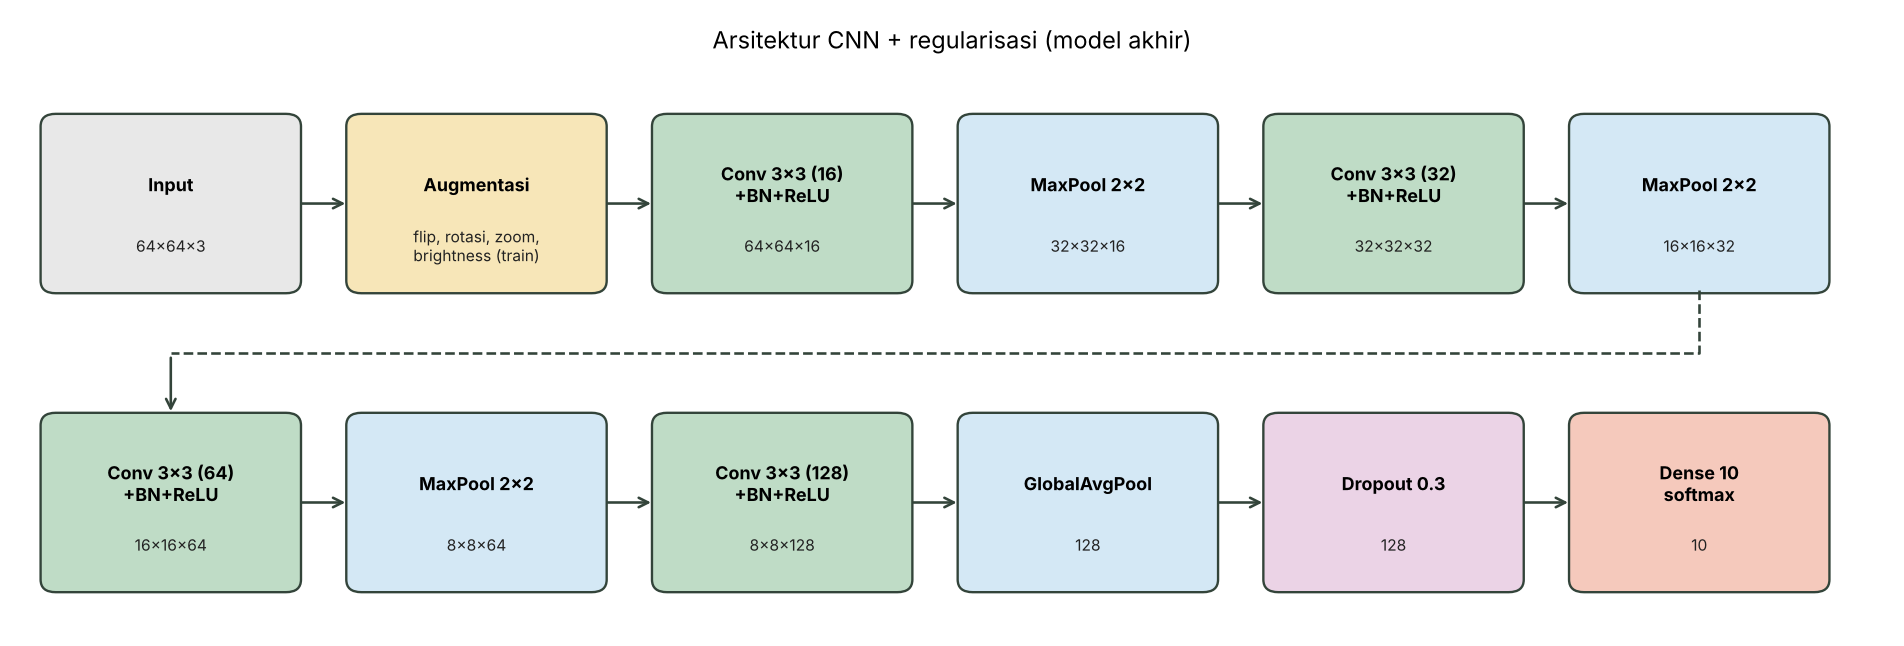

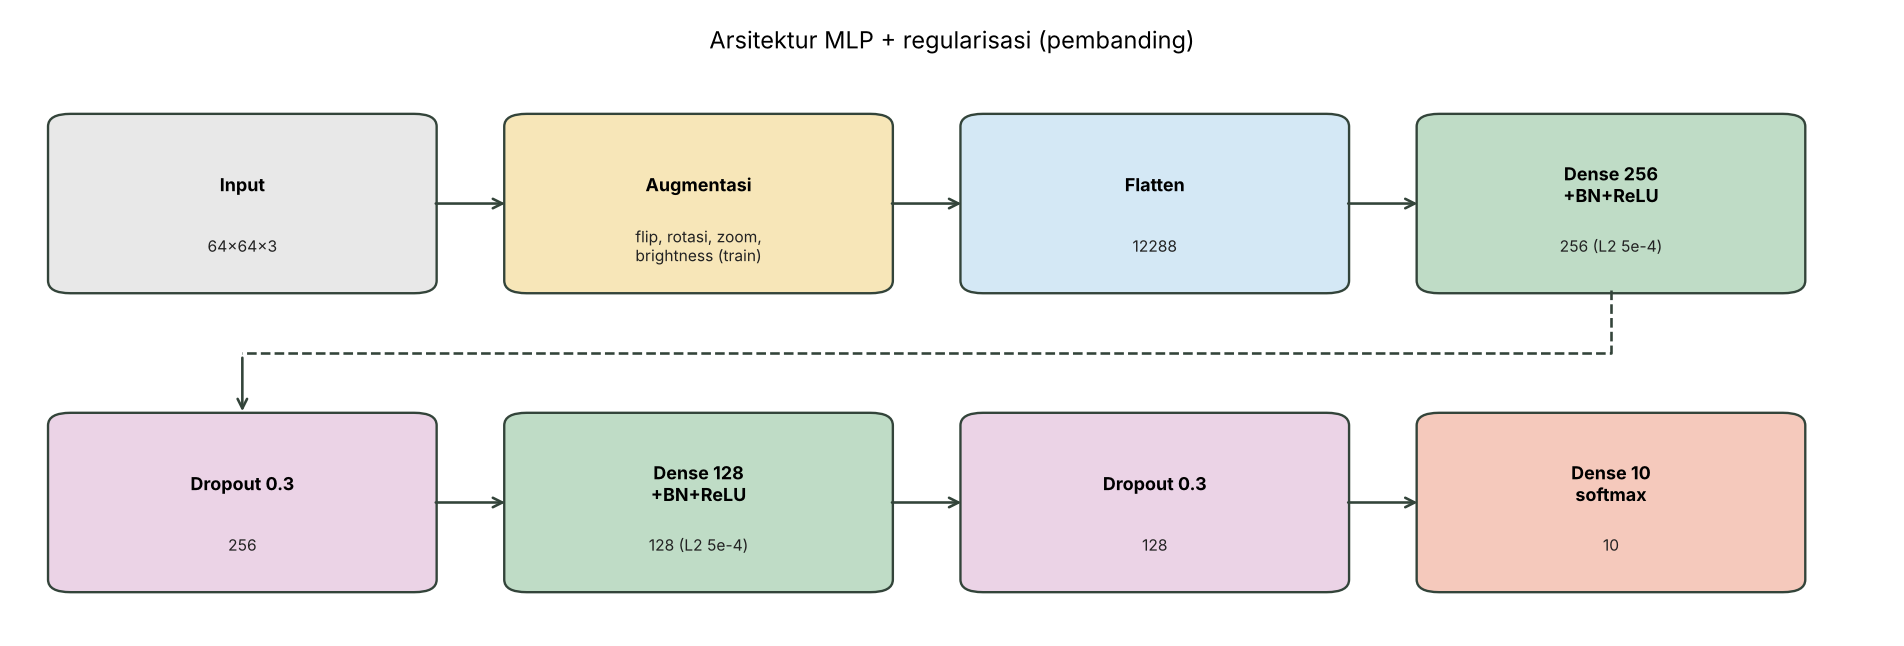

In [6]:
display(IPImage('figures/fig_arch_cnn.png', width=820)); display(IPImage('figures/fig_arch_mlp.png', width=820))

## 6. Pelatihan
Konfigurasi: Adam (lr 1e-3), batch 64, maks 30 epoch, loss sparse categorical crossentropy, EarlyStopping (val_loss, patience 6).
Versi teregulasi menambah BatchNorm (momentum 0,9), Dropout 0,3, L2 5e-4, augmentasi, class weight, ReduceLROnPlateau.

,skenario,params,epoch_dijalankan,epoch_terbaik,detik_per_epoch,val_acc,test_acc,test_macroF1
0,CNN_baseline,684490,21,15,32.3,0.9489,0.9460,0.9299
1,CNN_reg,99450,18,14,42.6,0.9302,0.9255,0.9088
2,MLP_baseline,3180170,27,21,5.3,0.8178,0.8139,0.7682
3,MLP_reg,3181322,18,18,19.3,0.8270,0.8249,0.7844


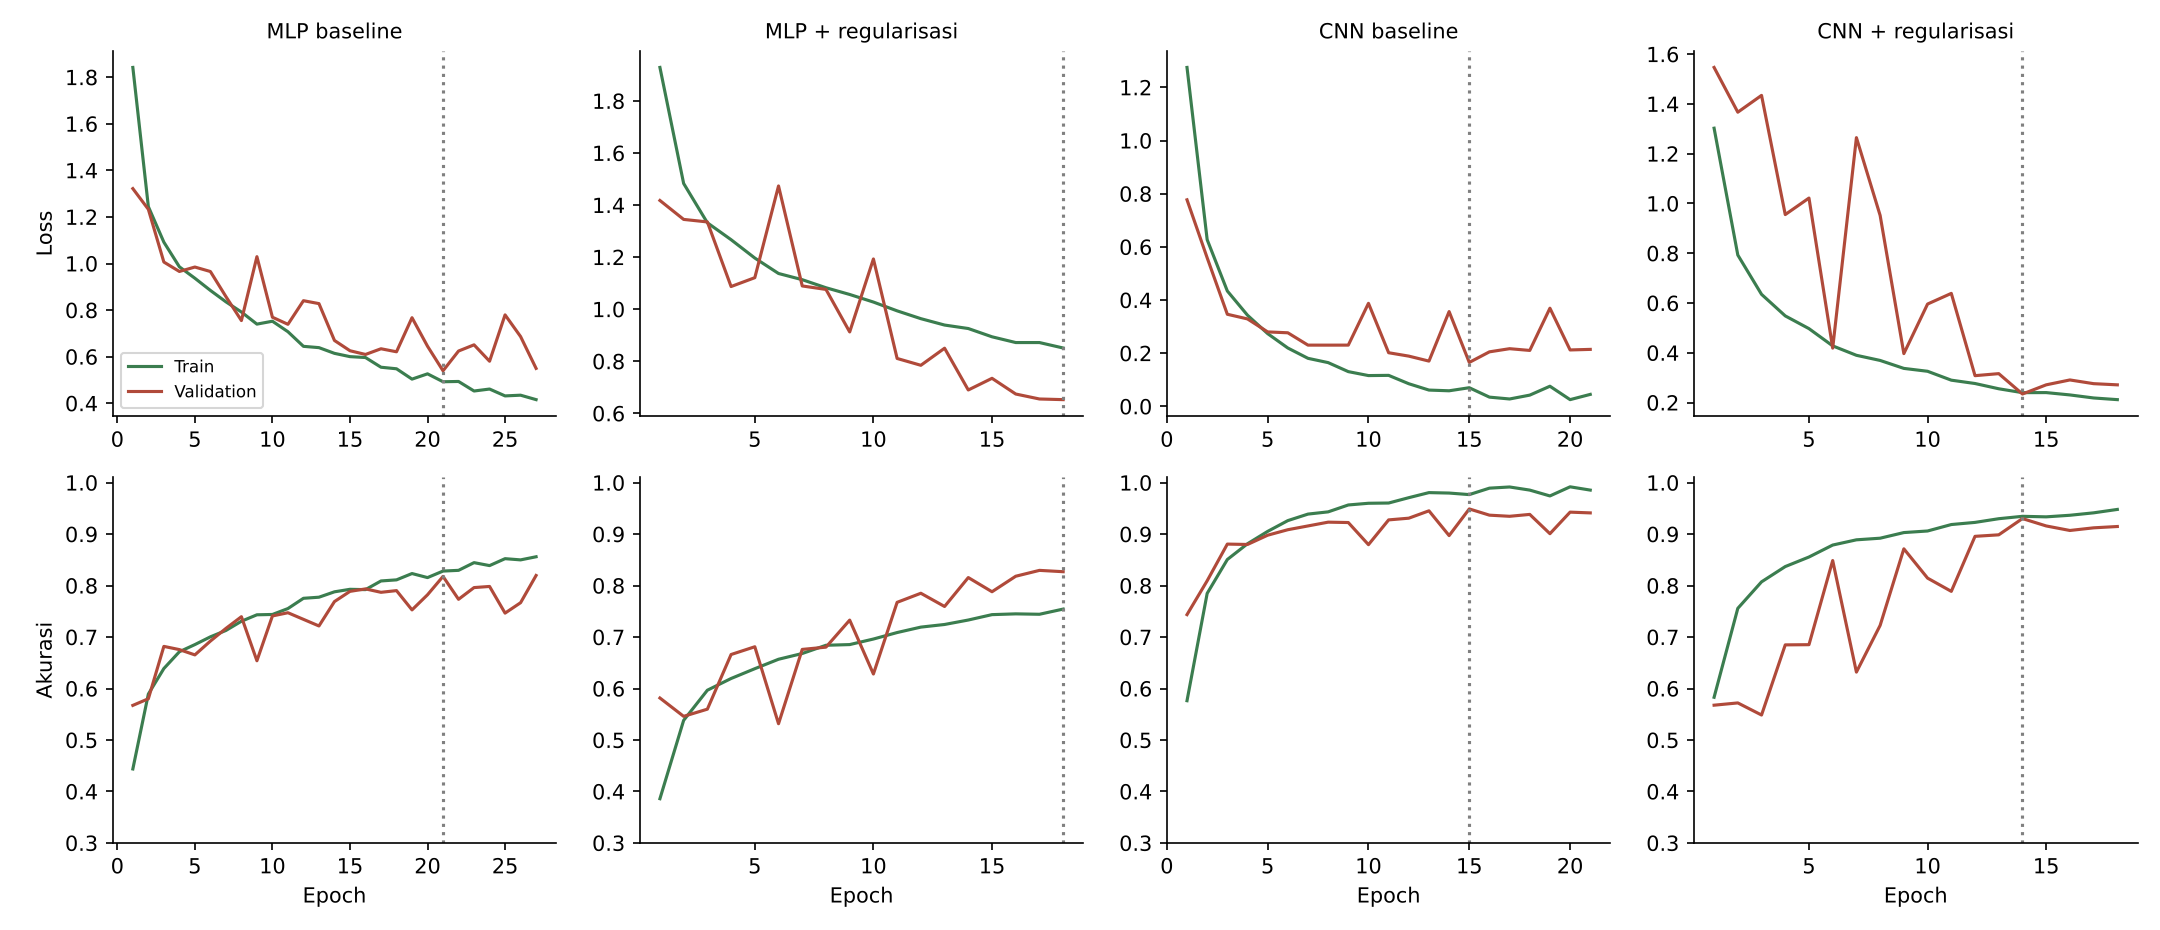

In [7]:
if RETRAIN:
    !python run_all.py
res = {}
for p in sorted(glob.glob("results/*.json")):
    n = os.path.basename(p)[:-5]
    r = json.load(open(p))
    if not isinstance(r, dict) or "params" not in r: continue      # lewati JSON non-skenario
    res[n] = r
rows = [dict(skenario=n, params=r["params"], epoch_dijalankan=r["epochs_run"], epoch_terbaik=r["best_epoch"], detik_per_epoch=r["sec_per_epoch"],
             val_acc=round(r["val_acc"], 4), test_acc=round(r["acc"], 4), test_macroF1=round(r["macro_f1"], 4)) for n, r in res.items()]
display(pd.DataFrame(rows))
display(IPImage("figures/fig_curves_main.png", width=900))

## 7. Evaluasi pada data uji

,model,acc,macro_p,macro_r,macro_f1,weighted_f1,val_acc,params,epochs,best_epoch,sec_epoch,train_min
0,MLP baseline,0.8139,0.7911,0.7563,0.7682,0.8104,0.8178,3180170,27,21,5.3,2.4
1,MLP + regularisasi,0.8249,0.7720,0.8147,0.7844,0.8256,0.8270,3181322,18,18,19.3,5.8
2,CNN baseline,0.9460,0.9331,0.9272,0.9299,0.9458,0.9489,684490,21,15,32.3,11.6
3,CNN + regularisasi,0.9255,0.9098,0.9196,0.9088,0.9266,0.9302,99450,18,14,42.6,12.8


,model,acc,macro_p,macro_r,macro_f1,weighted_f1,val_acc,params,epochs,best_epoch,sec_epoch,train_min
0,CNN + regularisasi,0.9255,0.9098,0.9196,0.9088,0.9266,0.9302,99450,18,14,42.6,12.8


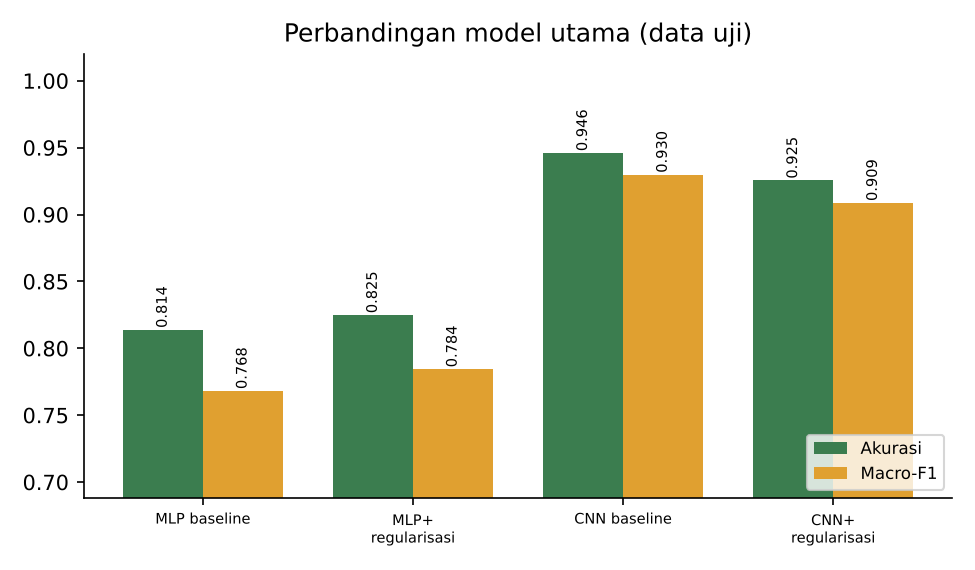

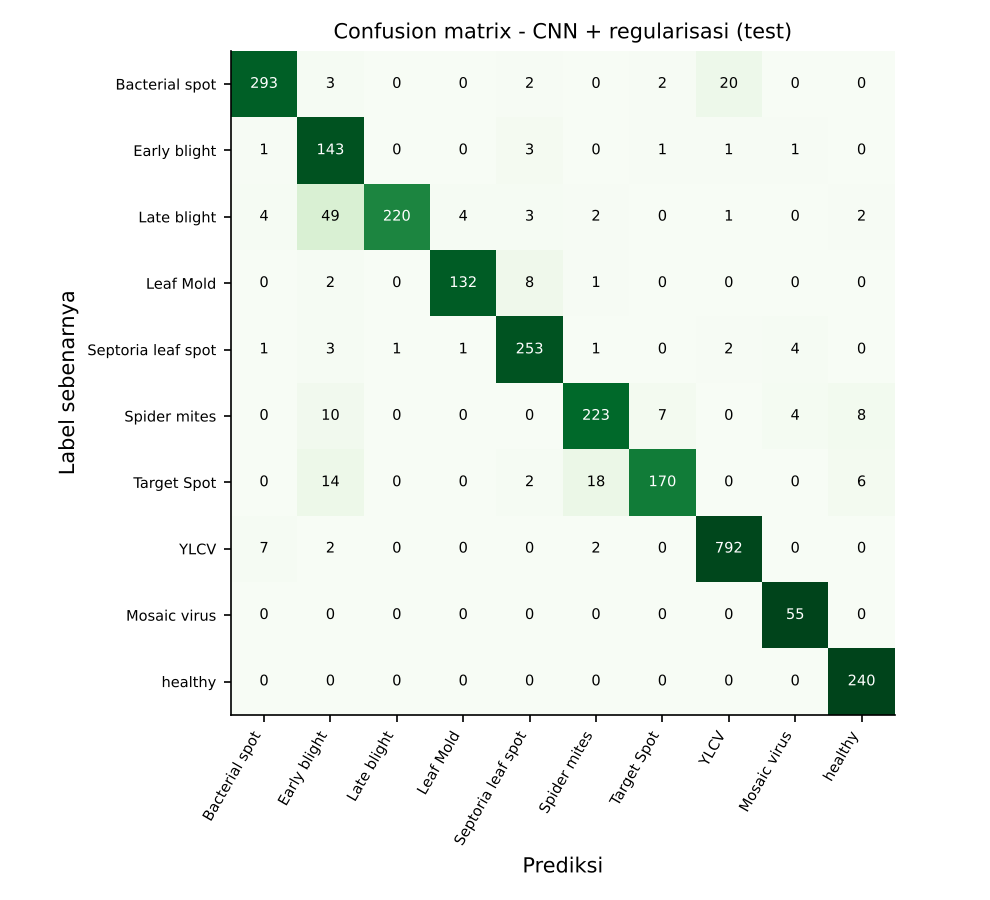

Kesalahan terbanyak CNN + regularisasi: [{'true': 'Late_blight', 'pred': 'Early_blight', 'count': 49}, {'true': 'Bacterial_spot', 'pred': 'Tomato_Yellow_Leaf_Curl_Virus', 'count': 20}, {'true': 'Target_Spot', 'pred': 'Spider_mites', 'count': 18}, {'true': 'Target_Spot', 'pred': 'Early_blight', 'count': 14}, {'true': 'Spider_mites', 'pred': 'Early_blight', 'count': 10}, {'true': 'Spider_mites', 'pred': 'healthy', 'count': 8}]


In [8]:
A = json.load(open("results/analysis.json"))
display(pd.DataFrame(A["main_table"]).round(4))
if A.get("ablation_table"): display(pd.DataFrame(A["ablation_table"]).round(4))
display(IPImage("figures/fig_model_compare.png", width=900))
display(IPImage("figures/fig_cm_cnn_reg.png", width=520))
print("Kesalahan terbanyak CNN + regularisasi:", A["top_confusions"])

## 8. Dua fitur unik
**Fitur 1 - Grad-CAM**: peta area penentu prediksi; bukti dampak: uji *deletion* (menghapus area Grad-CAM tertinggi vs piksel acak).
**Fitur 2 - Confidence threshold**: prediksi dengan keyakinan < tau ditolak; bukti dampak: *selective classification* dan penolakan 600 daun non-tomat.

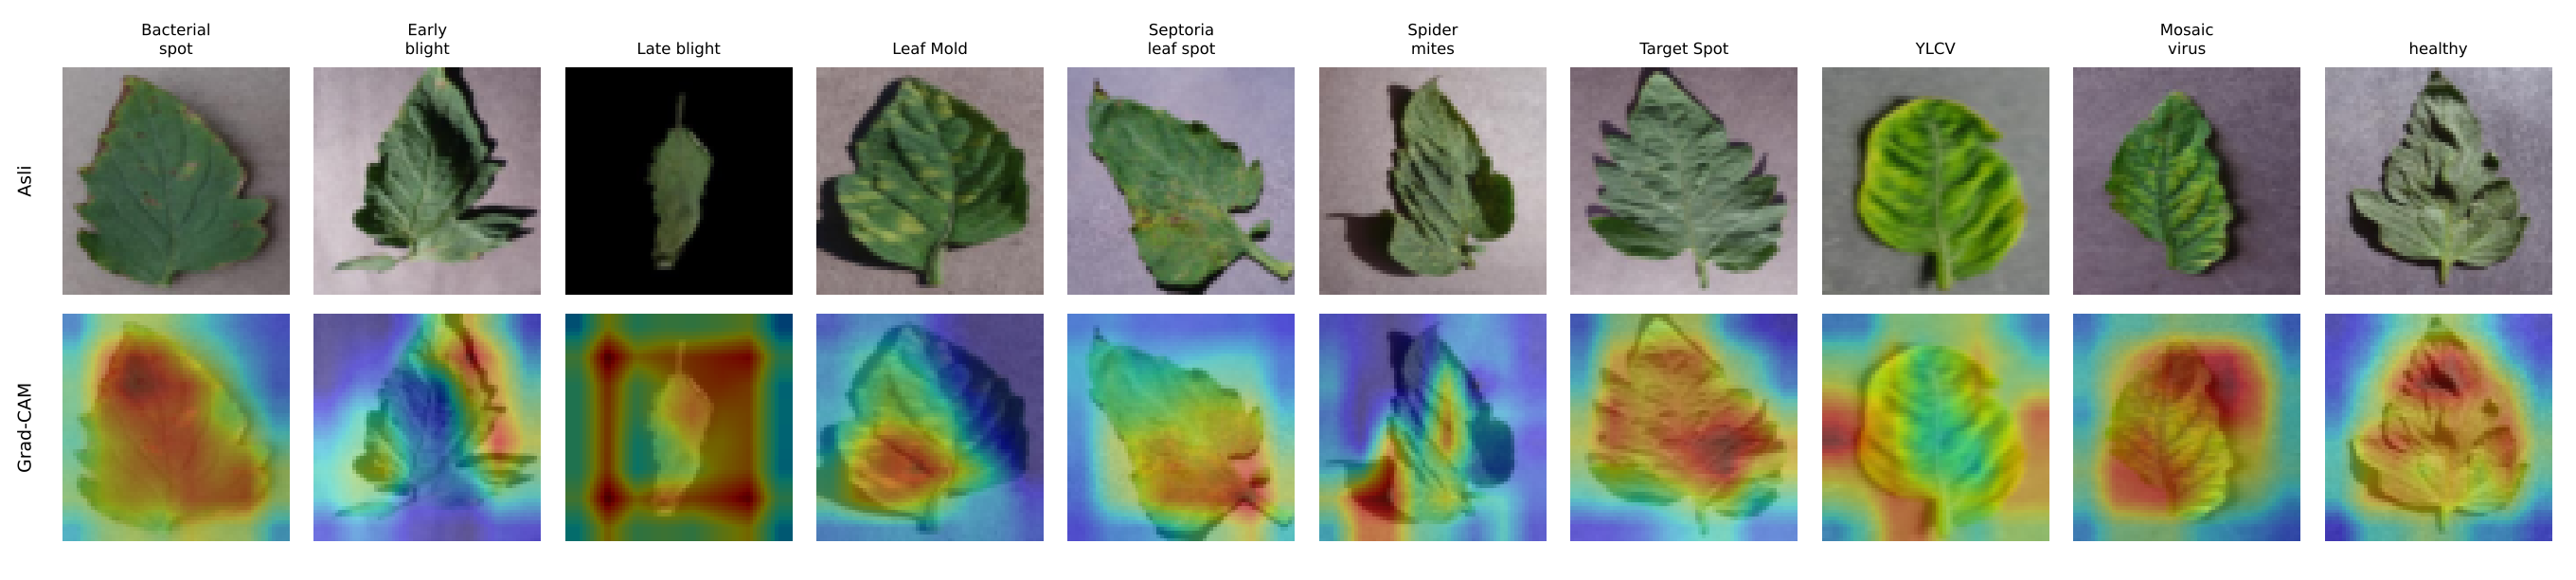

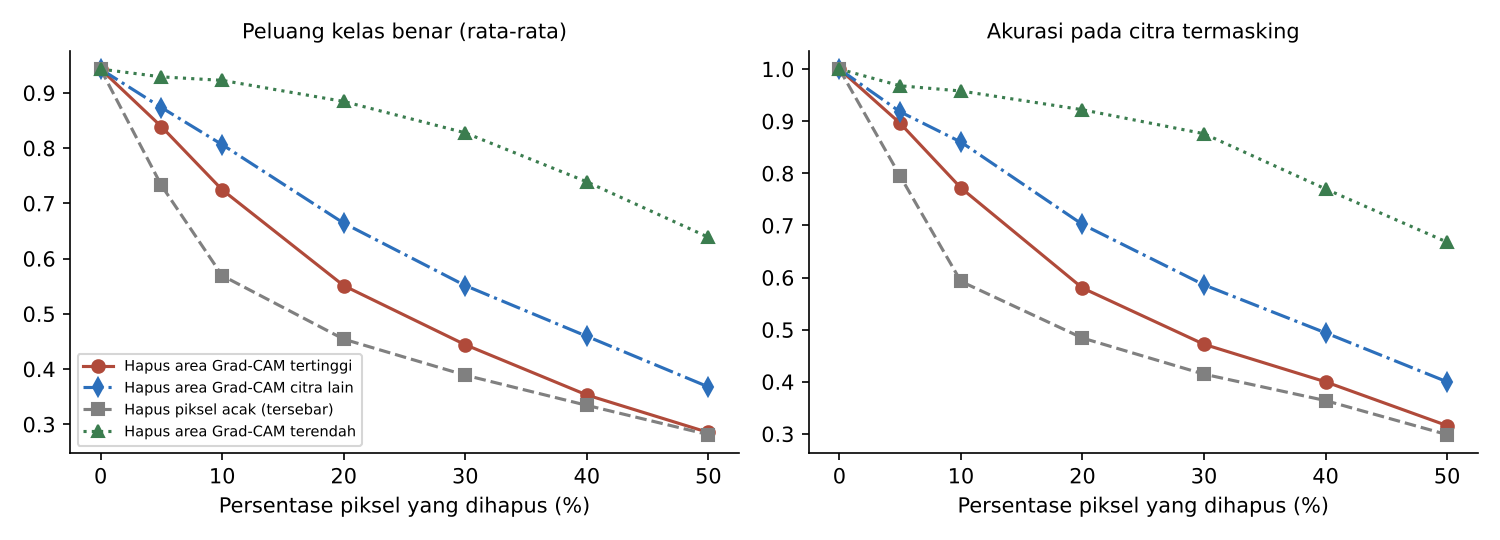

Peluang kelas benar setelah menghapus piksel (persen): [0, 5, 10, 20, 30, 40, 50]
  Grad-CAM tertinggi: [0.943, 0.8389, 0.7245, 0.5511, 0.4441, 0.3532, 0.2852]
  Acak              : [0.943, 0.7325, 0.5692, 0.4542, 0.389, 0.3344, 0.2813]
  Grad-CAM terendah : [0.943, 0.929, 0.9227, 0.8845, 0.8277, 0.739, 0.6387]


In [9]:
display(IPImage("figures/fig_gradcam_correct.png", width=900))
display(IPImage("figures/fig_deletion.png", width=800))
d = A["deletion"]
print("Peluang kelas benar setelah menghapus piksel (persen):", [int(x * 100) for x in d["fractions"]])
print("  Grad-CAM tertinggi:", d["gradcam_prob"]); print("  Acak              :", d["random_prob"]); print("  Grad-CAM terendah :", d["inverse_prob"])

tau terpilih = 0.945 | nilai terkecil pada grid 0.005 sehingga akurasi prediksi-diterima pada validation >= 0.99


,tau,coverage,accuracy_accepted,ood_rejected,id_rejected,errors_remaining
0,0.000,1.0000,0.9255,0.0000,0.0000,203
1,0.500,0.9791,0.9348,0.1800,0.0209,174
2,0.700,0.8990,0.9600,0.4350,0.1010,98
3,0.800,0.8513,0.9707,0.5400,0.1487,68
4,0.900,0.7658,0.9818,0.6983,0.2342,38
5,0.950,0.6953,0.9916,0.7967,0.3047,16
6,0.990,0.5029,0.9985,0.9583,0.4971,2
7,0.945,0.7048,0.9896,0.7900,0.2952,20


OOD: {'n_ood': 600, 'auroc_msp': 0.8276, 'id_msp_mean': 0.922, 'ood_msp_mean': 0.7299, 'fpr_at_95tpr': 0.71, 'ood_rejected_at_tau': 0.79, 'id_accepted_at_tau': 0.7048, 'per_crop_rejected': {'Grape': 0.8266666666666667, 'Pepper,_bell': 0.7066666666666667, 'Potato': 0.78, 'Strawberry': 0.8466666666666667}, 'per_crop_pred': {'Grape': 'Septoria_leaf_spot', 'Pepper,_bell': 'Septoria_leaf_spot', 'Potato': 'Septoria_leaf_spot', 'Strawberry': 'Septoria_leaf_spot'}}


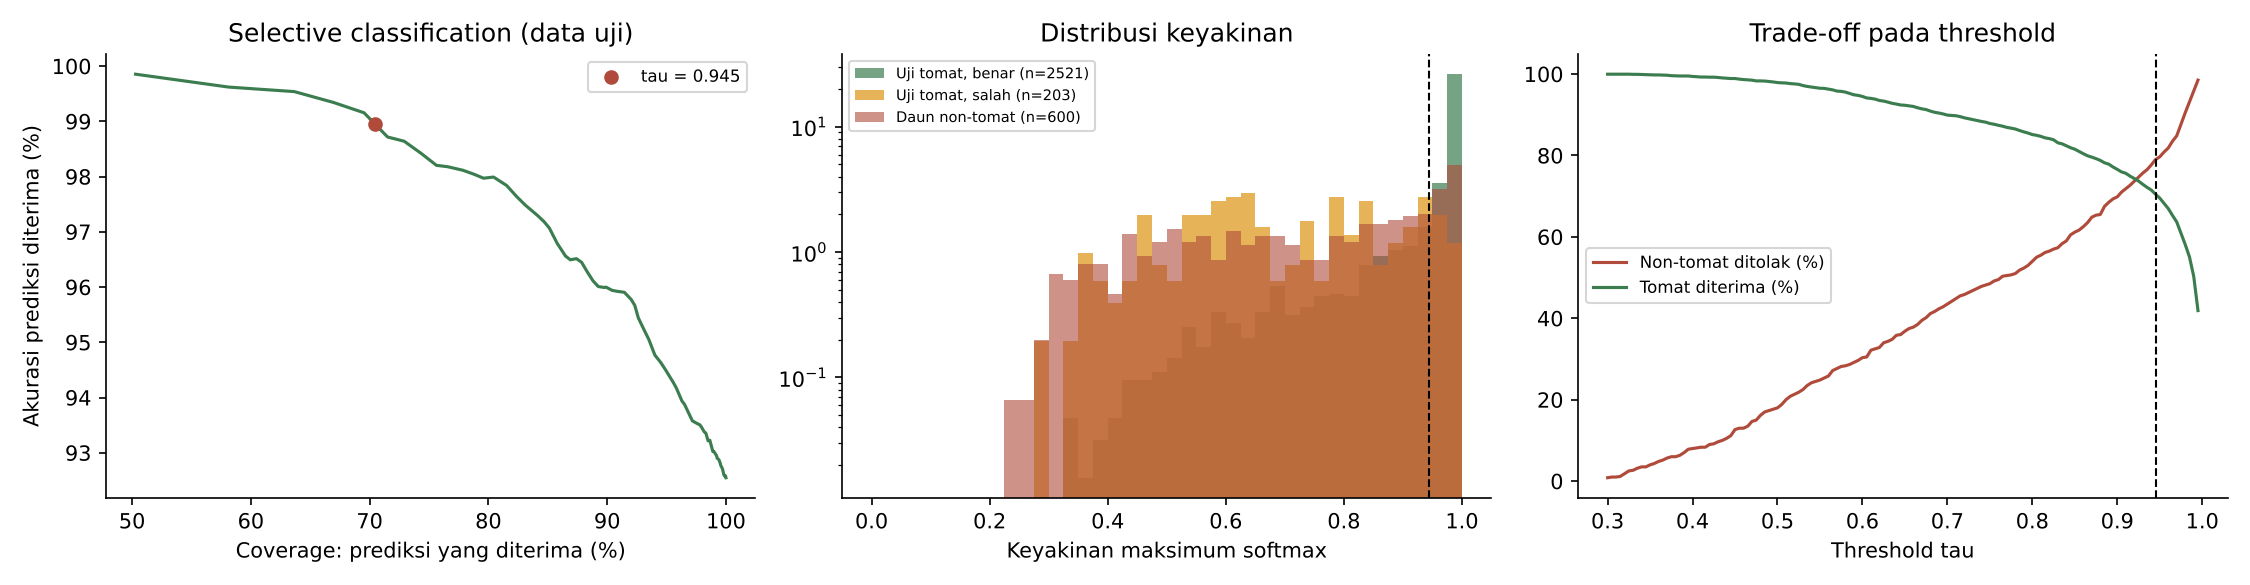

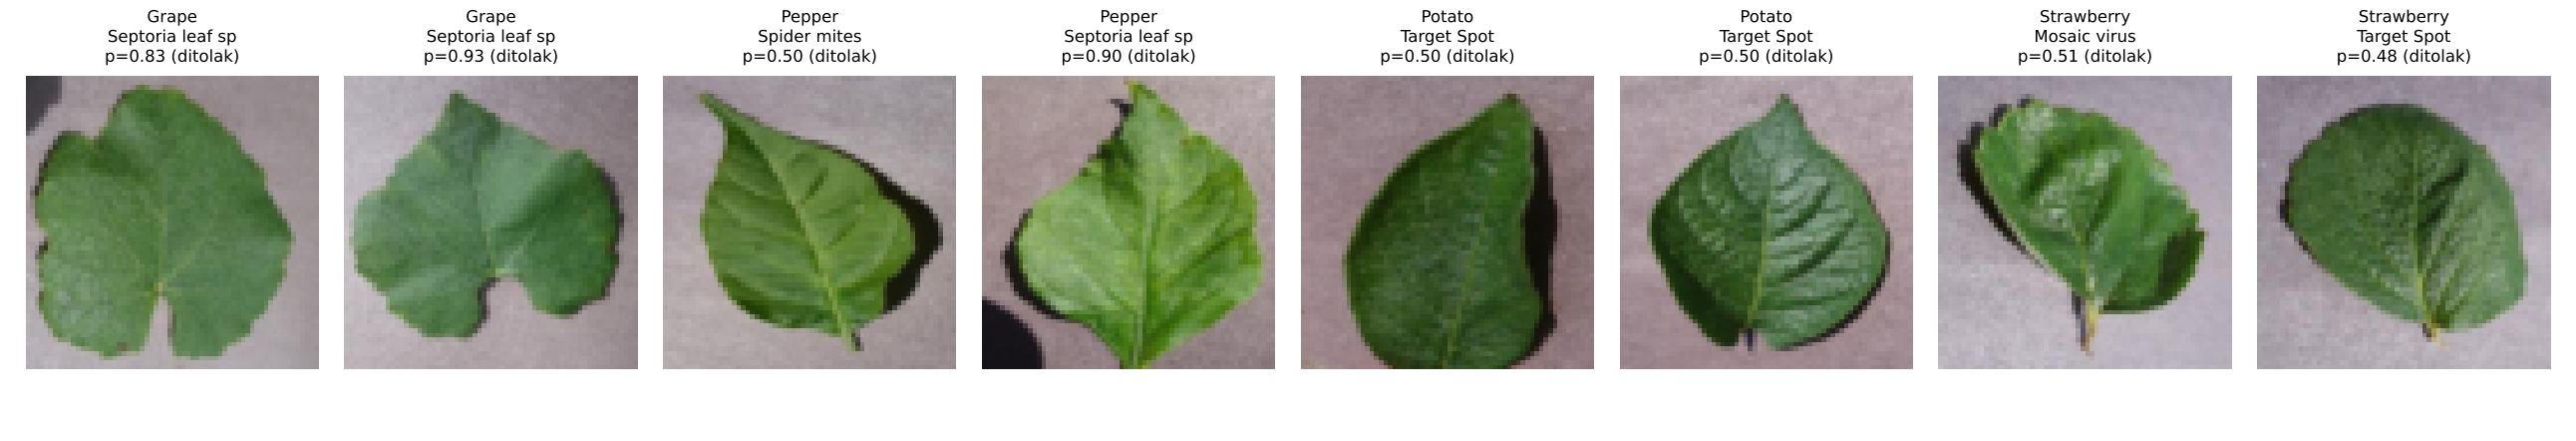

In [10]:
print("tau terpilih =", A["tau"], "|", A["tau_rule"])
display(pd.DataFrame(A["threshold_table"]).round(4))
print("OOD:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in A["ood"].items()})
display(IPImage("figures/fig_threshold_ood.png", width=900))
display(IPImage("figures/fig_ood_examples.png", width=900))

## 9. Inferensi (kelas `Predictor`)

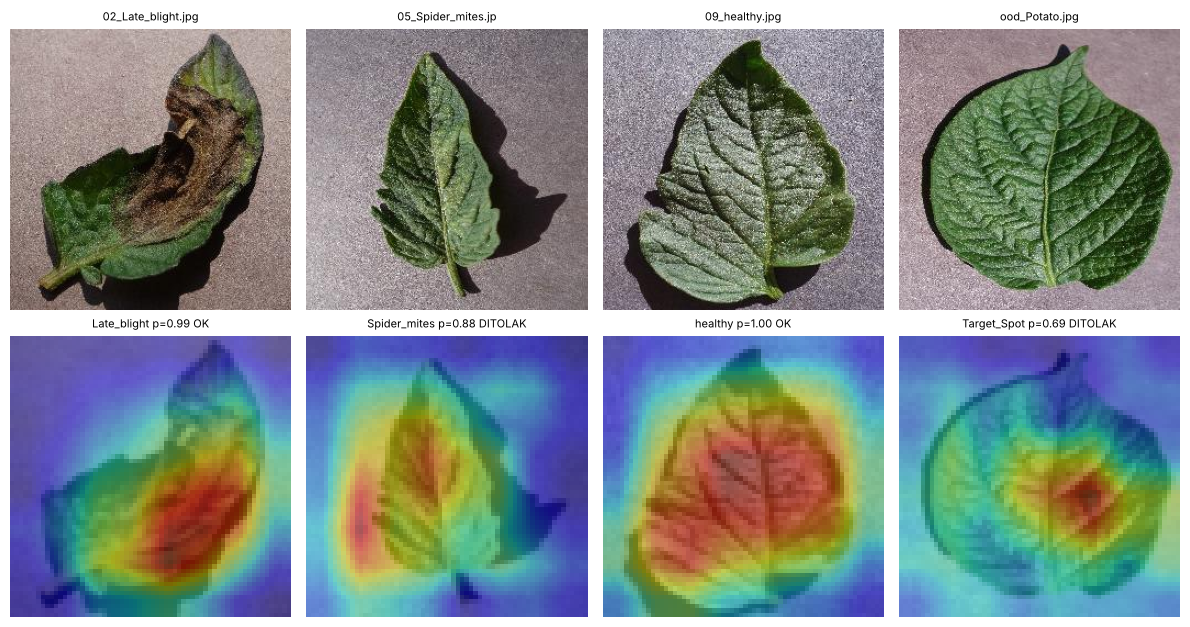

In [11]:
from inference import Predictor, overlay, CLASS_NAMES, LABEL_ID
from PIL import Image
pr = Predictor("results/CNN_reg_final.keras", tau=A["tau"])
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
files = sorted(glob.glob("app/examples/*.jpg"))
pick = [f for f in files if any(k in f for k in ("02_Late", "05_Spider", "09_healthy", "ood_Potato"))]
for j, fp in enumerate(pick):
    out = pr.predict(Image.open(fp))
    axes[0, j].imshow(Image.open(fp)); axes[0, j].axis("off")
    axes[0, j].set_title(os.path.basename(fp)[:18], fontsize=8)
    axes[1, j].imshow(overlay(out["x"], out["cam"])); axes[1, j].axis("off")
    axes[1, j].set_title(f"{out['label'][:16]} p={out['confidence']:.2f} " + ("OK" if out["accepted"] else "DITOLAK"), fontsize=8)
plt.tight_layout(); plt.show()